<a href="https://colab.research.google.com/github/julia-zhmurko/JuliaZhmurko-ML/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D1%96_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B8/%D0%9B%D0%A05_%D0%96%D0%BC%D1%83%D1%80%D0%BA%D0%BE_%D0%AE%D0%BB%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_10_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D1%96_%D1%80%D1%8F%D0%B4%D0%B8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

**Автор:** студентка групи ФІТ 4-10 Жмурко Юлія Андріївна

**Була присутня на парі (07.10.2026)**

In [1]:
# Імпортуйте необхідні бібліотеки
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

warnings.filterwarnings("ignore")
plt.style.use("default")

###**Пояснення:**

Імпортуємо необхідні бібліотеки для роботи з кліматичними даними, їх попередньої обробки, аналізу та візуалізації.

Бібліотеки `NumPy` та `Pandas` використовуватимемо для обробки даних, `Matplotlib` і `Seaborn` - для побудови графіків, `Scikit-learn` - для масштабування даних та оцінювання точності прогнозів, `Statsmodels` - для аналізу автокореляцій і побудови моделі `ARIMA`, а `TensorFlow/Keras` — для реалізації нейронної мережі `LSTM`.

In [2]:
# Завантажте датасет з Kaggle
import kagglehub

path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Path to dataset files:", path)

100%|██████████| 194k/194k [00:00<00:00, 36.3MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/yug201/daily-climate-time-series-data-delhi-india/versions/1


###**Пояснення:**

Завантажимо датасет **Daily Weather Time Series Data (Delhi, India)** з платформи Kaggle за допомогою бібліотеки `kagglehub`. Для цього використаємо функцію `dataset_download()`, вказавши ідентифікатор набору даних.

Шлях до завантажених файлів збережемо у змінній `path` та виведемо на екран для подальшого імпорту даних у середовище Google Colab.

In [3]:
# Зчитайте датасет у DataFrame та перегляньте дані
print("Файли датасету:", os.listdir(path))

file_path = os.path.join(path, "kaggel_weather_2013_to_2024.csv")
df = pd.read_csv(file_path)

print("\nПерші 5 рядків датасету:")
display(df.head())

print("\nІнформація про датасет:\n")
df.info()

print("\nСтатистичні характеристики:\n")
display(df.describe())

Файли датасету: ['kaggel_weather_2013_to_2024.csv']

Перші 5 рядків датасету:


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Інформація про датасет:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 no

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


**DATE**:	Дата проведення метеорологічного спостереження

**tempmax**:	Максимальна температура повітря, °C

**tempmin**:	Мінімальна температура повітря, °C

**temp**:	Середня температура повітря, °C

**feelslikemax**:	Максимальна відчутна температура, °C

**feelslikemin**:	Мінімальна відчутна температура, °C

**feelslike**:	Середня відчутна температура, °C

**humidity**:	Відносна вологість повітря, %

**precip**:	Кількість атмосферних опадів, мм

**precipprob**:	Імовірність випадання опадів, %

**precipcover**:	Частка періоду з опадами, %

**windspeed**:	Швидкість вітру

**sealevelpressure**:	Атмосферний тиск, приведений до рівня моря

**conditions**:	Текстовий опис погодних умов

**Year**:	Рік спостереження

**month**:	Місяць спостереження

**dayofweek**:	День тижня

**dayofyear**:	Порядковий номер дня в році

**year-2000**:	Кількість років від 2000 року

**weekofyear**:	Номер тижня в році

**tempmax_humidity**:	Добуток максимальної температури та вологості

**tempmin_humidity**:	Добуток мінімальної температури та вологості

**temp_humidity**:	Добуток середньої температури та вологості

**feelslikemax_humidity**:	Добуток максимальної відчутної температури та вологості

**feelslikemin_humidity**:	Добуток мінімальної відчутної температури та вологості

**feelslike_humidity**:	Добуток середньої відчутної температури та вологості

**temp_range**:	Добовий діапазон температури

**heat_index**:	Розрахунковий індекс теплового навантаження

###**Пояснення:**

Зчитаємо завантажений CSV-файл у DataFrame `df` за допомогою функції `pd.read_csv()` бібліотеки Pandas.

Для ознайомлення зі структурою датасету використаємо методи `head()`, `info()` та `describe()`, які дозволяють переглянути перші 5 рядків, типи даних, кількість непорожніх значень та основні статистичні характеристики.

У результаті встановлено, що датасет містить **3557 записів та 29 стовпців**, які характеризують кліматичні показники, зокрема температуру, вологість, опади, швидкість вітру та атмосферний тиск.

Стовпець `DATE` має тип `object`, тому потребує перетворення у формат `datetime`. За результатами `info()` пропущених значень у стовпцях не виявлено.

Підготовка даних

In [4]:
# Виконайте попередню обробку даних:
# - DATE -> datetime
# - сортування за датою
# - видалення зайвих колонок
# - встановлення DATE як індексу

# Перетворення DATE у формат datetime
df["DATE"] = pd.to_datetime(df["DATE"], format = "%m/%d/%Y")

# Сортування даних за датою
df = df.sort_values(by = "DATE")

# Видалення зайвого стовпця
df = df.drop(columns = ["Unnamed: 0"])

# Встановлення DATE як індексу
df = df.set_index("DATE")

print("Дані після попередньої обробки:")
display(df.head())

print("\nПеріод спостережень:")
print("Початок:", df.index.min())
print("Кінець:", df.index.max())

Дані після попередньої обробки:


,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
DATE,,,,,,,,,,,,,,,,,,,,,
2013-04-14,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
2013-04-15,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2013-04-16,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
2013-04-17,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
2013-04-18,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038



Період спостережень:
Початок: 2013-04-14 00:00:00
Кінець: 2024-11-30 00:00:00


###**Пояснення:**

Виконаємо попередню обробку даних для подальшого аналізу часових рядів. За допомогою функції `pd.to_datetime()` перетворимо стовпець `DATE` у формат `datetime`, відсортуємо записи за датою методом `sort_values()` та видалимо зайвий стовпець `Unnamed: 0`.

Після цього встановимо `DATE` як часовий індекс `DataFrame` за допомогою методу `set_index()`.

У результаті попередньої обробки отримано датасет із 3557 записів та 27 стовпців. Період спостережень охоплює дати з 14.04.2013 по 30.11.2024.

In [5]:
# Перегляньте інформацію про структуру датасету
print("Інформація про структуру датасету:\n")
df.info()

Інформація про структуру датасету:

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                   3557 non-null   int64  
 14  mo

###**Пояснення:**

Переглянемо структуру датасету після попередньої обробки за допомогою методу `info()`, який дозволяє визначити кількість записів і стовпців, типи даних та кількість непорожніх значень.

У результаті встановлено, що датасет містить 3557 записів та 27 стовпців, серед яких 19 мають тип `float64`, 7 - `int64` та 1 - `object`. Індексом `DataFrame` є `DatetimeIndex`, а всі стовпці містять по 3557 непорожніх значень, що свідчить про відсутність пропущених значень у наявних записах датасету.

In [6]:
# Перевірте наявність пропущених значень
print("Кількість пропущених значень у стовпцях:")
display(df.isnull().sum())

print("\nЗагальна кількість пропущених значень:",
      df.isnull().sum().sum())

Кількість пропущених значень у стовпцях:


,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0
precipcover,0



Загальна кількість пропущених значень: 0


###**Пояснення:**

Перевіримо датасет на наявність пропущених значень за допомогою методів `isnull()` та `sum()`, які дозволяють визначити кількість відсутніх значень у кожному стовпці та їх загальну кількість.

У результаті перевірки встановлено, що **всі 27 стовпців датасету не містять пропущених значень**, а їх загальна кількість дорівнює 0.

Графік температури

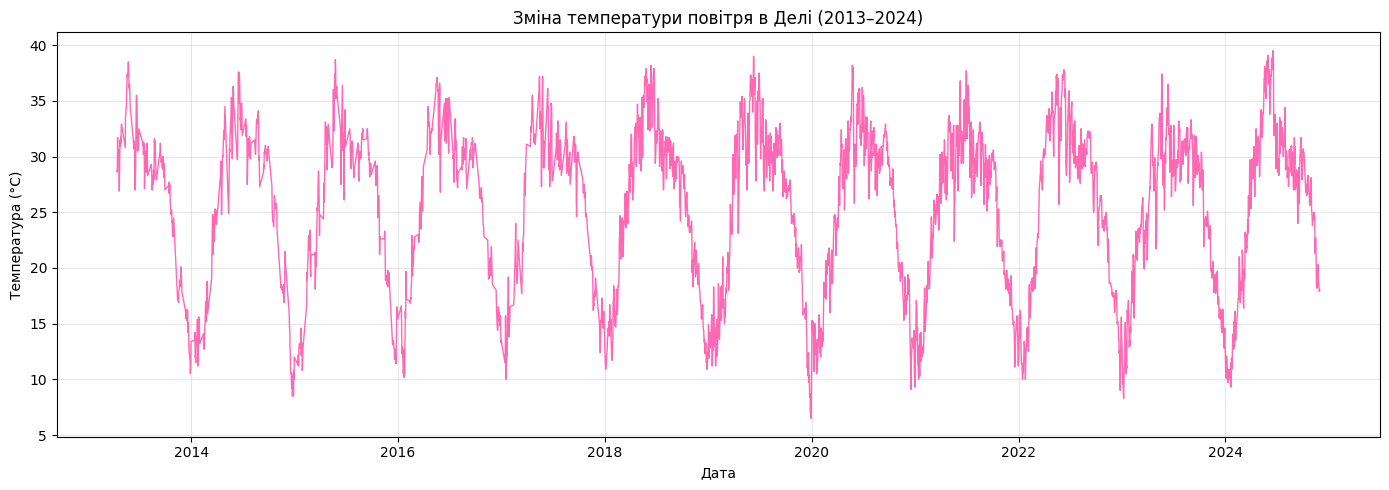

In [7]:
# Побудуйте графік зміни температури у часі
plt.figure(figsize = (14, 5))

plt.plot(df.index, df["temp"], color = "hotpink", linewidth = 1)

plt.title("Зміна температури повітря в Делі (2013–2024)")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")

plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

###**Пояснення:**

Побудуємо графік зміни середньої температури повітря в часі за допомогою функції `plot()` бібліотеки `Matplotlib`.

По осі X відобразимо дати спостережень, а по осі Y — значення температури зі стовпця `temp`.

На отриманому графіку спостерігаються **чітко виражені сезонні коливання температури** протягом 2013–2024 років.

Найвищі значення температури припадають на теплі періоди року та досягають приблизно 35–40 °C, тоді як у холодні періоди температура знижується приблизно до 10–15 °C, іноді й нижче.

Подібний характер коливань повторюється щороку, що свідчить про наявність сезонності у часовому ряді.

Ковзне середнє

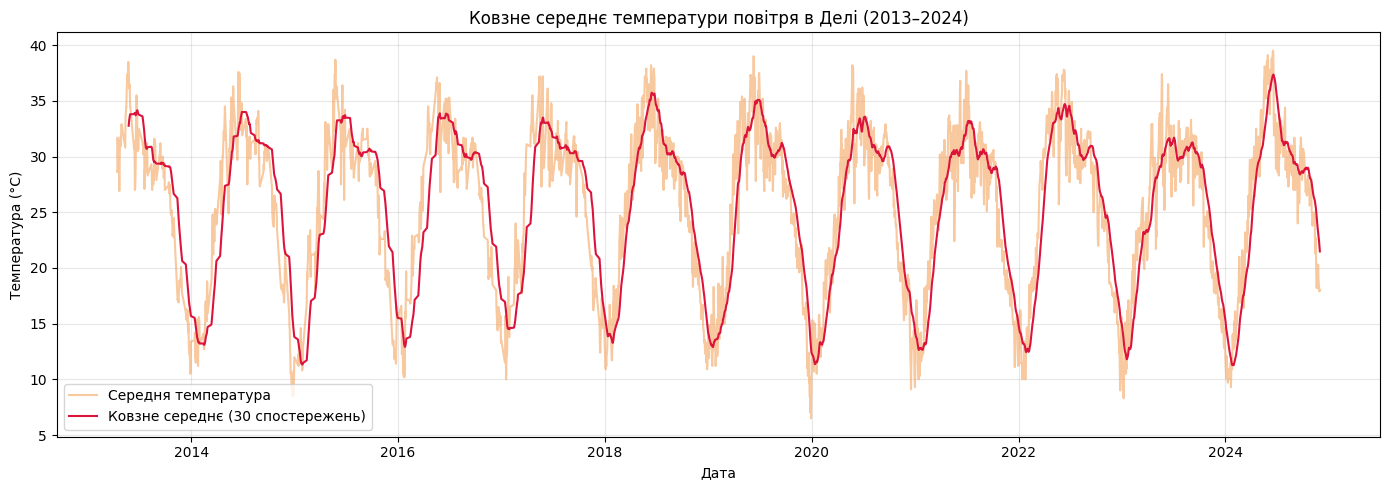

In [8]:
# Обчисліть та візуалізуйте ковзне середнє температури
df["temp_rolling"] = df["temp"].rolling(window = 30).mean()

plt.figure(figsize = (14, 5))

plt.plot(df.index, df["temp"],
         label = "Середня температура",
         color = "sandybrown", alpha = 0.6)

plt.plot(df.index, df["temp_rolling"],
         label = "Ковзне середнє (30 спостережень)",
         color = "crimson", linewidth = 1.5)

plt.title("Ковзне середнє температури повітря в Делі (2013–2024)")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")

plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

###**Пояснення:**

Обчислимо ковзне середнє значення температури повітря за допомогою методу `rolling()` з вікном у 30 спостережень та функції `mean()`.

Отримані значення збережемо у новому стовпці `temp_rolling`.

Для візуалізації побудуємо графік за допомогою бібліотеки `Matplotlib`, на якому відобразимо початкові значення температури та її ковзне середнє.

На отриманому графіку видно, що **ковзне середнє згладжує короткострокові коливання температури**, дозволяючи чіткіше простежити загальні тенденції її зміни.

Спостерігаються регулярні сезонні коливання з підвищенням температури в теплі періоди року та зниженням у холодні.

Отже, використання ковзного середнього підтверджує наявність вираженої сезонності у часовому ряді.

Розподіл температури

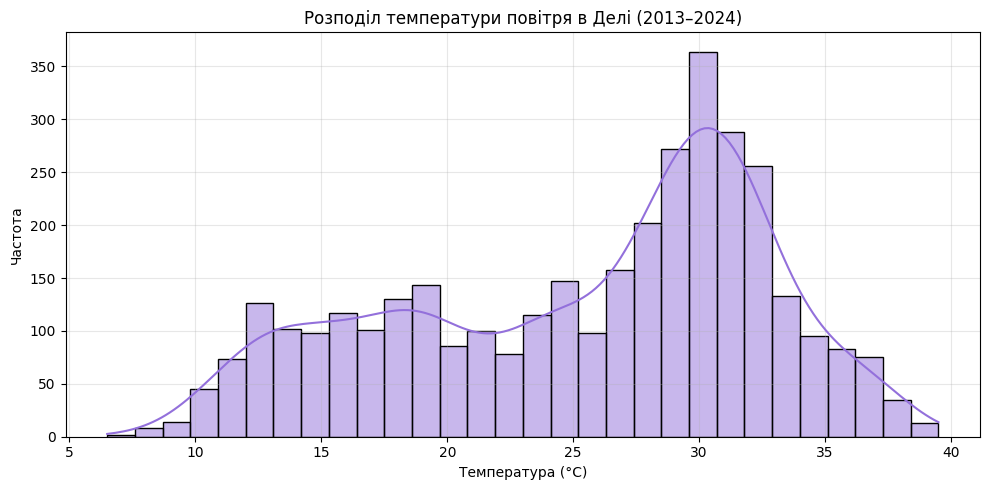

In [9]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(10, 5))

sns.histplot(df["temp"], bins = 30, kde = True,
             color = "mediumpurple", edgecolor = "black")

plt.title("Розподіл температури повітря в Делі (2013–2024)")
plt.xlabel("Температура (°C)")
plt.ylabel("Частота")

plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

###**Пояснення:**

Побудуємо гістограму розподілу середньої температури повітря за допомогою функції `histplot()` бібліотеки `Seaborn`.

Для цього використаємо значення температури зі стовпця `temp`, розділивши їх на 30 інтервалів за допомогою параметра `bins`.

Додатково відобразимо криву щільності розподілу `KDE` (`kde=True`), яка дозволяє наочніше оцінити характер розподілу температурних значень.

На отриманій гістограмі видно, що **найбільша частота спостережень припадає на температуру близько 29–32 °C**.

Також спостерігається менше скупчення значень у діапазоні приблизно 13–20 °C.

Отже, розподіл температури є нерівномірним та має декілька локальних максимумів, що може бути пов'язано із сезонними коливаннями температури протягом року.

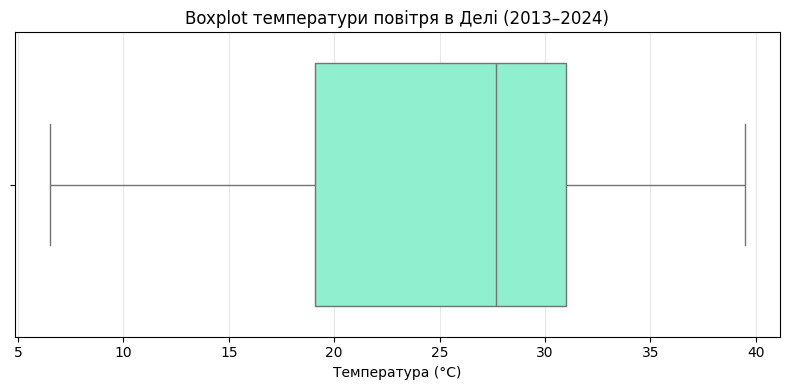

In [10]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize = (8, 4))

sns.boxplot(x = df["temp"], color = "aquamarine")

plt.title("Boxplot температури повітря в Делі (2013–2024)")
plt.xlabel("Температура (°C)")

plt.grid(axis = "x", alpha = 0.3)
plt.tight_layout()
plt.show()

###**Пояснення:**

Побудуємо діаграму розмаху (`boxplot`) для аналізу розподілу температури повітря та виявлення можливих викидів за допомогою функції `boxplot()` бібліотеки `Seaborn`.

Для цього використаємо значення температури зі стовпця `temp`.

На отриманій діаграмі видно, що **медіана температури становить приблизно 27,7 °C**, нижній квартиль - 19,1 °C, а верхній - 31 °C.

Мінімальне значення температури становить 6,5 °C, а максимальне - 39,5 °C.

Окремих точок за межами діаграми розмаху не спостерігається, що свідчить про **відсутність викидів**.

Отже, температурні значення мають досить широкий діапазон розподілу, що може бути пов'язано із сезонними коливаннями температури протягом року.

Аналіз автокореляції
ACF

PACF

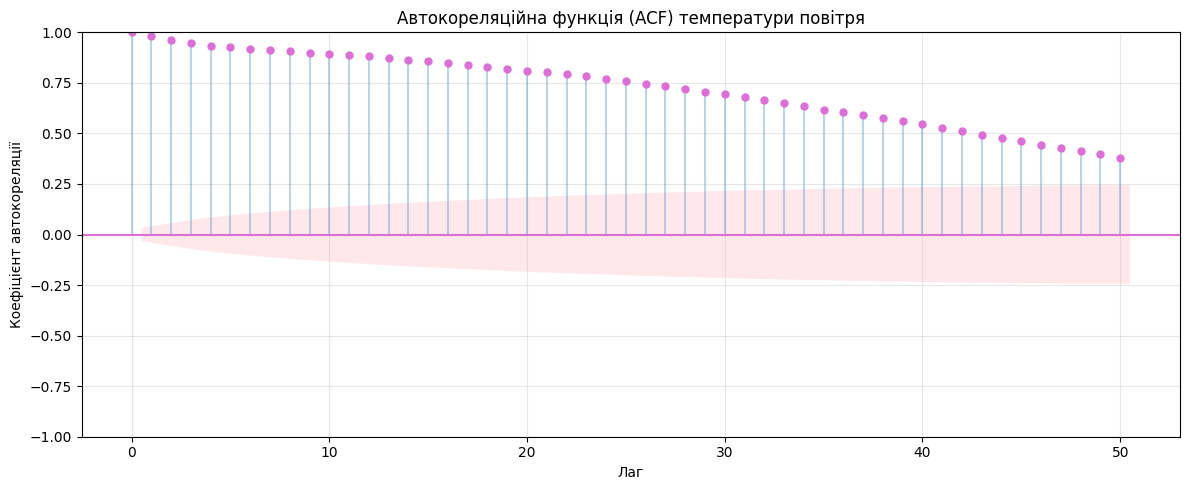

In [11]:
# Побудуйте графік автокореляційної функції (ACF)
fig, ax = plt.subplots(figsize = (12, 5))

plot_acf(df["temp"], lags = 50, ax = ax,
         color = "orchid")

for collection in ax.collections:
    collection.set_facecolor("lightpink")
    collection.set_alpha(0.3)

plt.title("Автокореляційна функція (ACF) температури повітря")
plt.xlabel("Лаг")
plt.ylabel("Коефіцієнт автокореляції")

plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

###**Пояснення:**

Побудуємо графік автокореляційної функції (`ACF`) для аналізу залежності поточних значень температури повітря від попередніх спостережень за допомогою функції `plot_acf()` бібліотеки `Statsmodels`.

Для цього використаємо значення температури зі стовпця `temp` та встановимо кількість лагів `lags=50`.

На отриманому графіку спостерігається **сильна додатна автокореляція між послідовними значеннями температури**.

На початкових лагах коефіцієнт автокореляції наближається до 1 та поступово зменшується приблизно до 0,35 на 50-му лагу.

Більшість значень виходять за межі довірчого інтервалу, що свідчить про статистично значущу залежність температури від попередніх спостережень.


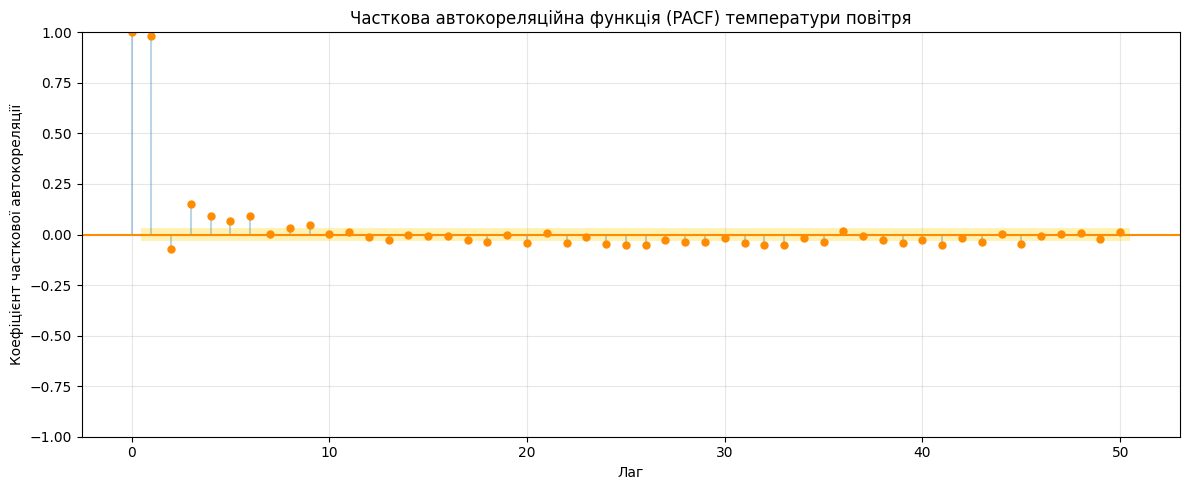

In [12]:
# Побудуйте графік часткової автокореляційної функції (PACF)
fig, ax = plt.subplots(figsize = (12, 5))

plot_pacf(df["temp"], lags = 50, ax = ax,
          method = "ywm", color = "darkorange")

for collection in ax.collections:
    collection.set_facecolor("gold")
    collection.set_alpha(0.3)

plt.title("Часткова автокореляційна функція (PACF) температури повітря")
plt.xlabel("Лаг")
plt.ylabel("Коефіцієнт часткової автокореляції")

plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

###**Пояснення:**

Побудуємо графік часткової автокореляційної функції (`PACF`) для аналізу безпосередньої залежності поточних значень температури повітря від попередніх спостережень за допомогою функції `plot_pacf()` бібліотеки `Statsmodels`.

Для цього використаємо значення температури зі стовпця `temp` та встановимо кількість лагів `lags=50`.

На отриманому графіку спостерігається **сильна додатна часткова автокореляція на першому лагу**, коефіцієнт якої наближається до 1.

На наступних лагах значення часткової автокореляції значно зменшуються, проте деякі з них виходять за межі довірчого інтервалу, що свідчить про наявність статистично значущих залежностей.

In [13]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
ts = df["temp"].copy()

ts = ts.sort_index()

train_size = int(len(ts) * 0.8)

train = ts.iloc[:train_size]
test = ts.iloc[train_size:]

print("Загальна кількість спостережень:", len(ts))
print("Тренувальна вибірка:", len(train))
print("Тестова вибірка:", len(test))

print("\nПеріод тренувальної вибірки:")
print(train.index.min(), "-", train.index.max())

print("\nПеріод тестової вибірки:")
print(test.index.min(), "-", test.index.max())

Загальна кількість спостережень: 3557
Тренувальна вибірка: 2845
Тестова вибірка: 712

Період тренувальної вибірки:
2013-04-14 00:00:00 - 2022-12-19 00:00:00

Період тестової вибірки:
2022-12-20 00:00:00 - 2024-11-30 00:00:00


###**Пояснення:**

Сформуємо цільовий часовий ряд температури повітря на основі стовпця `temp` та збережемо його у змінній `ts`.

Відсортуємо дані у хронологічному порядку за допомогою методу `sort_index()`, після чого розділимо часовий ряд на тренувальну та тестову вибірки у співвідношенні **80% / 20%** за допомогою методу `iloc`, зберігаючи часовий порядок спостережень.

У результаті отримано **3557 записів**, із яких **2845 використовуватимуться для навчання моделей**, а **712 - для тестування**.

Тренувальна вибірка охоплює період з 14.04.2013 по 19.12.2022, а тестова - з 20.12.2022 по 30.11.2024.

Такий розподіл дозволить оцінити точність моделей прогнозування на спостереженнях, які не використовувалися під час навчання.

ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
model_arima = ARIMA(train.to_numpy(), order = (5, 1, 2))

model_arima_fit = model_arima.fit()

forecast_arima = model_arima_fit.forecast(steps = len(test))

forecast_arima = pd.Series(forecast_arima, index = test.index)

print("Результати прогнозування ARIMA:")
display(forecast_arima.head())

Результати прогнозування ARIMA:


,0
DATE,
2022-12-20,14.895737
2022-12-21,15.071189
2022-12-22,15.161451
2022-12-23,15.179429
2022-12-24,15.200756


###**Пояснення:**

Побудуємо модель прогнозування часових рядів `ARIMA` за допомогою класу `ARIMA` бібліотеки `Statsmodels`.

Для цього використаємо тренувальну вибірку `train` та встановимо параметри моделі `order=(5, 1, 2)`, які визначають порядок авторегресії, диференціювання та ковзного середнього.

Навчимо модель за допомогою методу `fit()`, після чого сформуємо прогноз температури для тестової вибірки методом `forecast()`.

Отримані прогнозовані значення збережемо у змінній `forecast_arima` та виведемо перші 5 результатів.

У результаті прогнозування модель ARIMA визначила значення температури на період з 20.12.2022 по 24.12.2022 у діапазоні **від 14,90 °C до 15,20 °C**.

In [15]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(model_arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(5, 1, 2)   Log Likelihood               -4969.050
Date:                Tue, 20 Oct 2026   AIC                           9954.101
Time:                        05:00:38   BIC                          10001.724
Sample:                             0   HQIC                          9971.277
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.1810      0.227      0.799      0.424      -0.263       0.625
ar.L2          0.1094      0.205      0.533      0.594      -0.293       0.511
ar.L3         -0.1108      0.049     -2.242      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

###**Пояснення:**

Виведемо статистичний звіт навченої моделі `ARIMA(5,1,2)` за допомогою методу `summary()`, який містить оцінки параметрів моделі, їх статистичну значущість та основні показники якості прогнозування.

У результаті отримано значення **Log Likelihood = −4969,050, AIC = 9954,101, BIC = 10001,724 та sigma² = 1,9280**.

За результатами аналізу коефіцієнтів встановлено, що статистично значущими на рівні 0,05 є авторегресійні складові `ar.L3` та `ar.L5`, оскільки їхні значення p-value менші за 0,05.

Також тест Льюнга — Бокса (`Prob(Q) = 0,97`) не виявив статистично значущої автокореляції залишків на першому лагу.

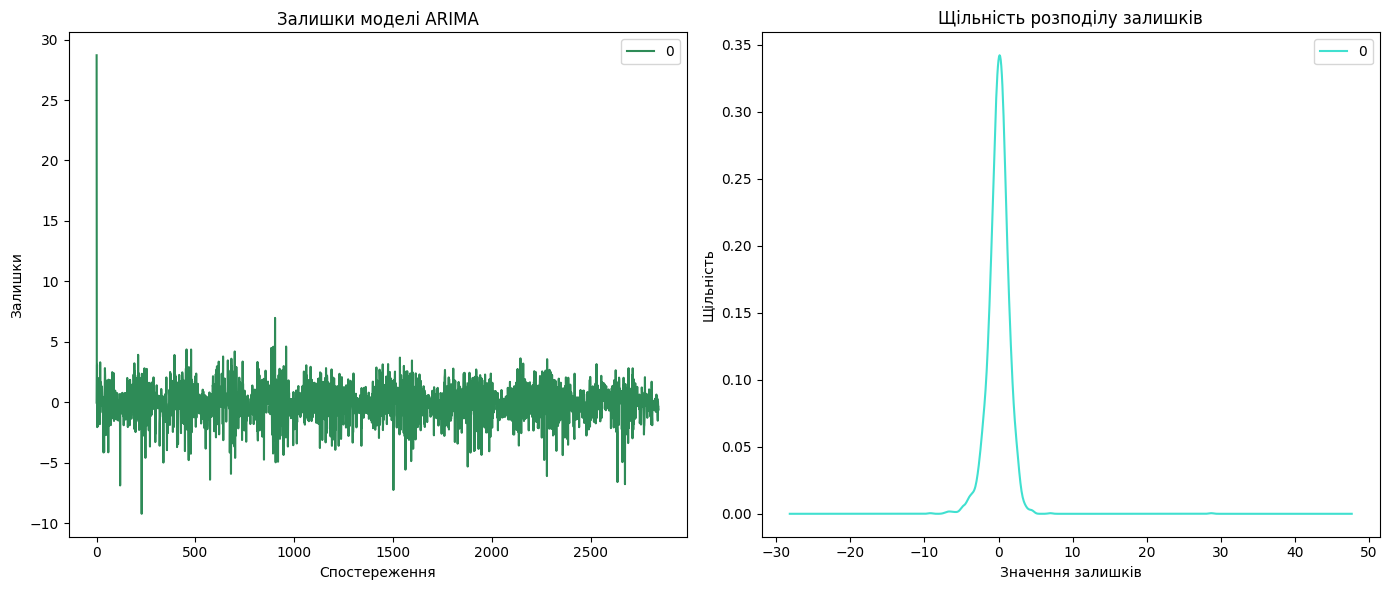

In [16]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
residuals = pd.DataFrame(model_arima_fit.resid)

fig, ax = plt.subplots(1, 2, figsize = (14, 6))

residuals.plot(title = "Залишки моделі ARIMA", ax = ax[0],
               color = "seagreen")

residuals.plot(kind = "kde", title = "Щільність розподілу залишків",
               ax = ax[1], color = "turquoise")

ax[0].set_xlabel("Спостереження")
ax[0].set_ylabel("Залишки")

ax[1].set_xlabel("Значення залишків")
ax[1].set_ylabel("Щільність")

plt.tight_layout()
plt.show()

###**Пояснення:**

Проаналізуємо залишки навченої моделі `ARIMA(5,1,2)` за допомогою атрибута `resid`, який містить різницю між фактичними та оціненими моделлю значеннями температури повітря.

Отримані залишки збережемо у DataFrame `residuals` та побудуємо два графіки: графік зміни залишків за послідовністю спостережень та графік щільності їх розподілу (`KDE`).

На першому графіку видно, що **залишки моделі переважно коливаються навколо нульового значення**, хоча спостерігаються окремі значні відхилення, зокрема на початку часового ряду.

Другий графік показує, що **основна частина залишків зосереджена поблизу нуля**, а їх розподіл має виражений центральний максимум.

In [17]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

mae_arima = mean_absolute_error(test.values, forecast_arima.values)

rmse_arima = np.sqrt(mean_squared_error(test.values, forecast_arima.values))

mape_arima = mape(test.values, forecast_arima.values)

print("Метрики точності моделі ARIMA(5,1,2):")
print(f"MAE: {mae_arima}")
print(f"RMSE: {rmse_arima}")
print(f"MAPE: {mape_arima}%")

Метрики точності моделі ARIMA(5,1,2):
MAE: 10.92780939502283
RMSE: 12.500912042764613
MAPE: 39.59198711988373%


###**Пояснення:**

Оцінимо точність прогнозування моделі `ARIMA(5,1,2)` за допомогою метрик `MAE`, `RMSE` та `MAPE`.

Для обчислення середньої абсолютної похибки використаємо функцію `mean_absolute_error()`, для `RMSE` - функцію `mean_squared_error()` із подальшим обчисленням квадратного кореня, а для `MAPE` реалізуємо окрему функцію `mape()`.

У результаті отримано значення **MAE = 10,93 °C, RMSE = 12,50 °C та MAPE = 39,59%**.

Це означає, що прогнозовані значення температури в середньому відрізняються від фактичних приблизно на 10,93 °C, що свідчить про досить високу похибку прогнозування моделі `ARIMA(5,1,2)` на тестовій вибірці.

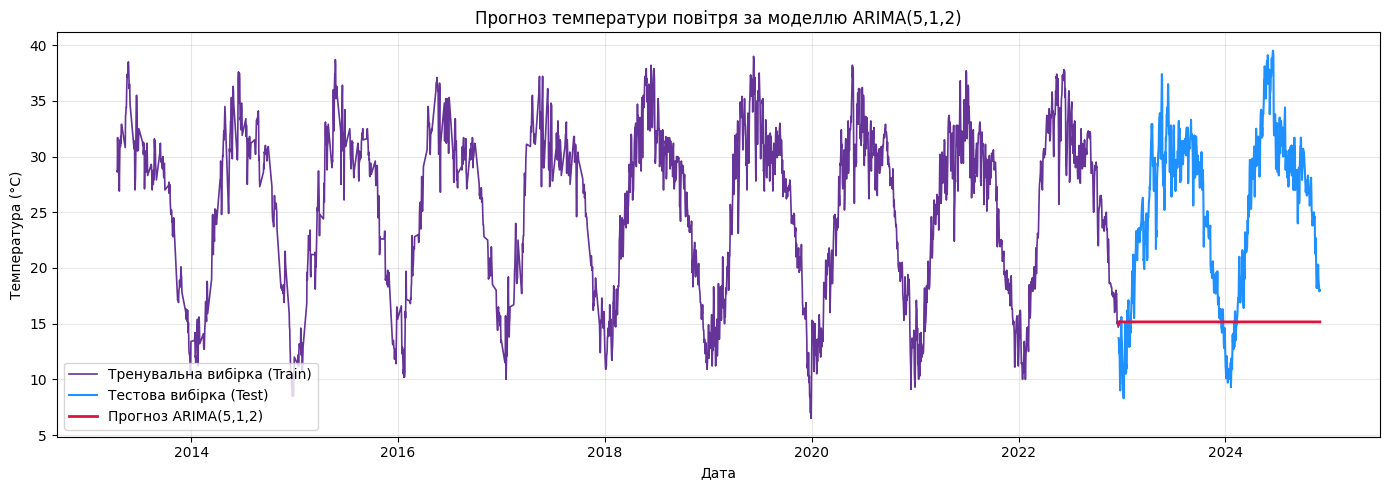

In [18]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize = (14, 5))

plt.plot(train.index, train.values,
         label = "Тренувальна вибірка (Train)",
         color = "rebeccapurple", linewidth = 1.2)

plt.plot(test.index, test.values,
         label = "Тестова вибірка (Test)",
         color = "dodgerblue", linewidth = 1.5)

plt.plot(test.index, forecast_arima.values,
         label = "Прогноз ARIMA(5,1,2)",
         color = "crimson", linewidth = 2)

plt.title("Прогноз температури повітря за моделлю ARIMA(5,1,2)")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")

plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

###**Пояснення:**

Побудуємо графік порівняння фактичних значень температури повітря та прогнозу моделі `ARIMA(5,1,2)` за допомогою функції `plot()` бібліотеки `Matplotlib`.

Для цього відобразимо тренувальну вибірку `train`, тестову вибірку `test` та прогнозовані значення `forecast_arima` на одному графіку.

На отриманому графіку видно, що **фактичні значення температури характеризуються вираженими сезонними коливаннями**, тоді як прогноз моделі `ARIMA` залишається майже постійним на рівні приблизно 15 °C протягом усього тестового періоду.

Це свідчить про те, що модель **не змогла відтворити сезонні зміни температури** та має значні відхилення від фактичних значень.

Отриманий результат узгоджується з раніше обчисленими метриками `MAE` = 10,93 °C, `RMSE` = 12,50 °C та `MAPE` = 39,59%, які вказують на недостатню точність довгострокового прогнозування моделі `ARIMA(5,1,2)`.

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
# Підготуйте дані у форматі, необхідному для Prophet
train_prophet = train.reset_index()
train_prophet.columns = ["ds", "y"]

test_prophet = test.reset_index()
test_prophet.columns = ["ds", "y"]

print("Тренувальні дані для Prophet:")
display(train_prophet.head())

print("\nТестові дані для Prophet:")
display(test_prophet.head())

print("\nРозміри вибірок:")
print("Train:", train_prophet.shape)
print("Test:", test_prophet.shape)

Тренувальні дані для Prophet:


,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6



Тестові дані для Prophet:


,ds,y
0,2022-12-20,13.7
1,2022-12-21,13.6
2,2022-12-22,12.4
3,2022-12-23,12.6
4,2022-12-24,11.8



Розміри вибірок:
Train: (2845, 2)
Test: (712, 2)


###**Пояснення:**

Підготуємо тренувальну та тестову вибірки у форматі, необхідному для побудови моделі Prophet.

Для цього за допомогою методу `reset_index()` перетворимо часовий індекс `DATE` на звичайний стовпець, після чого перейменуємо стовпці на `ds` та `y`, які відповідатимуть даті спостереження та значенню середньої температури повітря.

Отримані дані збережемо у DataFrame `train_prophet` та `test_prophet` і виведемо перші 5 рядків кожної вибірки для перевірки правильності перетворення.

У результаті отримано **тренувальну вибірку розміром 2845 × 2 та тестову вибірку розміром 712 × 2**.

In [20]:
!pip install prophet -q

In [21]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

model_prophet = Prophet(
    yearly_seasonality = True,
    weekly_seasonality = True,
    daily_seasonality = False
)

model_prophet.fit(train_prophet)

print("Модель Prophet успішно навчена!")

Модель Prophet успішно навчена!


###**Пояснення:**

Створимо модель прогнозування часових рядів `Prophet` за допомогою класу `Prophet` відповідної бібліотеки.

Для врахування сезонних закономірностей температури встановимо параметри `yearly_seasonality=True` та `weekly_seasonality=True`, які дозволяють моделі враховувати річні й тижневі коливання, а добову сезонність вимкнемо (`daily_seasonality=False`).

Навчимо створену модель на тренувальній вибірці `train_prophet` за допомогою методу `fit()`.

Прогноз

In [22]:
# Побудуйте прогноз Prophet для тестового періоду
forecast_prophet = model_prophet.predict(test_prophet[["ds"]])

pred_prophet = forecast_prophet["yhat"].values

print("Результати прогнозування Prophet:")
display(forecast_prophet[["ds", "yhat", "yhat_lower", "yhat_upper"]].head())

Результати прогнозування Prophet:


,ds,yhat,yhat_lower,yhat_upper
0,2022-12-20,13.892037,11.234290,16.449890
1,2022-12-21,13.738187,11.255277,16.417465
2,2022-12-22,13.534303,10.791438,16.093058
3,2022-12-23,13.344060,10.559555,15.940014
4,2022-12-24,13.189955,10.459047,15.696828


###**Пояснення:**

Побудуємо прогноз середньої температури повітря для тестового періоду за допомогою навченої моделі `Prophet`.

Для цього використаємо метод `predict()`, якому передамо дати спостережень зі стовпця `ds` тестової вибірки `test_prophet`.

Отримані результати збережемо у DataFrame `forecast_prophet`, який міститиме прогнозовані значення температури `yhat`, а також нижню `yhat_lower` та верхню `yhat_upper` межі прогнозного інтервалу.

Прогнозовані значення додатково збережемо у змінній `pred_prophet` для подальшого оцінювання точності моделі.

У результаті прогнозування отримано перші 5 значень температури за період з **20.12.2022 по 24.12.2022**, які поступово зменшуються приблизно від **13,89 °C до 13,19 °C**.

In [23]:
# Обчисліть MAE, RMSE, MAPE для Prophet
mae_prophet = mean_absolute_error(test.values, pred_prophet)

rmse_prophet = np.sqrt(mean_squared_error(test.values, pred_prophet))

mape_prophet = mape(test.values, pred_prophet)

print("Метрики точності моделі Prophet:")
print(f"MAE: {mae_prophet}")
print(f"RMSE: {rmse_prophet}")
print(f"MAPE: {mape_prophet}%")

Метрики точності моделі Prophet:
MAE: 2.004679994301011
RMSE: 2.5901965298397274
MAPE: 9.027934868552647%


###**Пояснення:**

Оцінимо точність прогнозування моделі `Prophet` за допомогою метрик `MAE`, `RMSE` та `MAPE`.

Для обчислення середньої абсолютної похибки використаємо функцію `mean_absolute_error()`, для `RMSE` - функцію `mean_squared_error()` із подальшим обчисленням квадратного кореня, а для `MAPE` - раніше створену функцію `mape()`.

У результаті отримано значення **MAE = 2,00 °C, RMSE = 2,59 °C та MAPE = 9,03%**. Це означає, що прогнозовані значення температури в середньому відрізняються від фактичних приблизно на 2 °C, що свідчить про досить високу точність прогнозування моделі `Prophet`.

Порівняно з раніше побудованою моделлю `ARIMA(5,1,2)`, для якої `MAE` = 10,93 °C, `RMSE` = 12,50 °C та `MAPE` = 39,59%, **модель Prophet продемонструвала значно кращі результати прогнозування**.

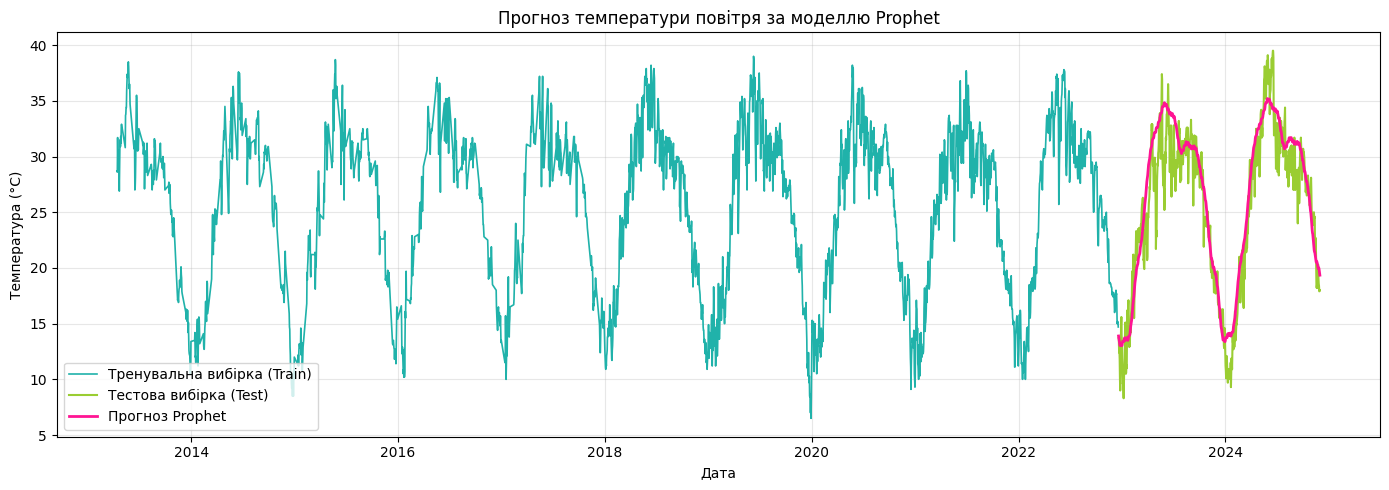

In [24]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize = (14, 5))

plt.plot(train.index, train.values,
         label = "Тренувальна вибірка (Train)",
         color = "lightseagreen", linewidth = 1.2)

plt.plot(test.index, test.values,
         label = "Тестова вибірка (Test)",
         color = "yellowgreen", linewidth = 1.5)

plt.plot(test_prophet["ds"], pred_prophet,
         label = "Прогноз Prophet",
         color = "deeppink", linewidth = 2)

plt.title("Прогноз температури повітря за моделлю Prophet")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")

plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

###**Пояснення:**

Побудуємо графік порівняння фактичних значень температури повітря та прогнозу моделі `Prophet` за допомогою функції `plot()` бібліотеки `Matplotlib`.

Для цього відобразимо тренувальну вибірку `train`, тестову вибірку `test` та прогнозовані значення `pred_prophet` на одному графіку.

На отриманому графіку видно, що **модель Prophet досить точно відтворює сезонні коливання температури повітря**, оскільки прогнозована крива переважно повторює характер змін фактичних значень температури протягом тестового періоду.

Спостерігаються окремі відхилення між прогнозованими та фактичними значеннями, проте модель правильно визначає періоди підвищення та зниження температури.

Отриманий результат узгоджується з раніше обчисленими метриками **MAE = 2,00 °C, RMSE = 2,59 °C та MAPE = 9,03%**, які свідчать про значно вищу точність прогнозування моделі `Prophet` порівняно з `ARIMA(5,1,2)`.

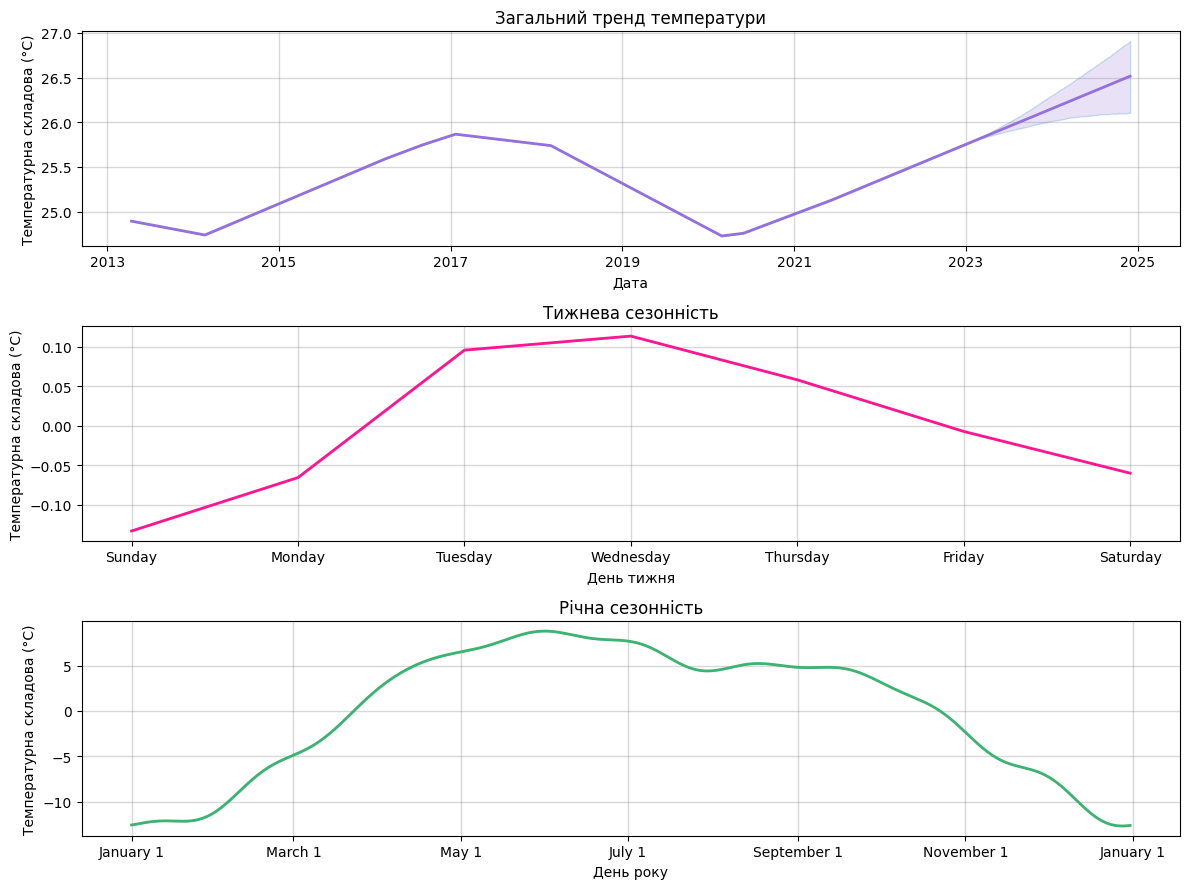

In [25]:
# Побудуйте компоненти моделі Prophet
full_dates = pd.DataFrame({"ds": ts.index.unique().sort_values()})
forecast_prophet_full = model_prophet.predict(full_dates)

fig = model_prophet.plot_components(forecast_prophet_full)

titles = ["Загальний тренд температури",
          "Тижнева сезонність",
          "Річна сезонність"]

colors = ["mediumpurple", "deeppink", "mediumseagreen"]

xlabels = ["Дата", "День тижня", "День року"]

for ax, title, color, xlabel in zip(fig.axes, titles, colors, xlabels):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Температурна складова (°C)")

    for line in ax.lines:
        line.set_color(color)
        line.set_linewidth(2)

    for collection in ax.collections:
        collection.set_facecolor(color)
        collection.set_alpha(0.2)

    ax.grid(True, alpha = 0.3)

fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()

###**Пояснення:**

Побудуємо графіки основних компонентів навченої моделі `Prophet` за допомогою методу `plot_components()`.

Для цього використаємо прогноз `forecast_prophet_full`, на основі якого відобразимо загальний тренд, тижневу та річну сезонність температури повітря.

На отриманих графіках видно, що **загальний тренд температури має змінний характер**: спостерігається підвищення температурної складової до 2017 року, зниження до 2020 року та подальше поступове зростання.

Тижнева сезонність характеризується незначними коливаннями, найбільший додатний вплив спостерігається у вівторок і середу, а найбільший від'ємний - у неділю.

**Річна сезонність виражена значно сильніше**, з найбільшими додатними значеннями температурної складової у травні–червні та найбільшими від'ємними у грудні–січні.

Отже, модель `Prophet` враховує сезонні закономірності зміни температури повітря, серед яких найбільше значення має річна сезонність, що сприяє точнішому прогнозуванню температури протягом року.

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [26]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
scaler = MinMaxScaler(feature_range = (0, 1))
scaled_data = scaler.fit_transform(ts.values.reshape(-1, 1))

def create_sequences(data, time_steps = 30):
    X, y = [], []

    for i in range(time_steps, len(data)):
        X.append(data[i-time_steps:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

time_steps = 30
X, y = create_sequences(scaled_data, time_steps)

X = X.reshape(X.shape[0], X.shape[1], 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (3527, 30, 1)
y shape: (3527,)


###**Пояснення:**

Підготуємо часовий ряд температури повітря для побудови нейронної мережі `LSTM`.

За допомогою `MinMaxScaler` виконаємо масштабування температурних значень до діапазону від 0 до 1.

Для формування вхідних послідовностей створимо функцію `create_sequences()`, яка використовуватиме 30 попередніх спостережень для прогнозування наступного значення температури.

Отримані дані збережемо у масивах `X` та `y`, після чого змінимо форму масиву `X` відповідно до вимог нейронної мережі `LSTM`.

У результаті сформовано **3527 послідовностей**, кожна з яких містить 30 попередніх значень температури.

Розмір масиву `X` становить `(3527, 30, 1)`, а масиву цільових значень `y` - `(3527,)`.

In [27]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (2821, 30, 1)
X_test shape: (706, 30, 1)
y_train shape: (2821,)
y_test shape: (706,)


###**Пояснення:**

Розділимо сформовані послідовності температурних значень на тренувальну та тестову вибірки у співвідношенні 80% / 20% без перемішування даних, зберігаючи їх часовий порядок.

Для цього використаємо змінну `split_index`, яка визначатиме межу розділення масивів `X` та `y`.

У результаті отримано **2821 тренувальну та 706 тестових послідовностей**.

Розмір масиву `X_train` становить `(2821, 30, 1)`, а `X_test` - `(706, 30, 1)`, тобто кожна послідовність містить 30 попередніх значень температури та одну ознаку.

Відповідні цільові значення збережено у масивах `y_train` та `y_test`.

In [28]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
model_lstm = Sequential([
    LSTM(50, return_sequences = True,
         input_shape = (X_train.shape[1], X_train.shape[2])),
    LSTM(50),
    Dense(1)
])

model_lstm.compile(optimizer = "adam", loss = "mean_squared_error")

print("Модель LSTM успішно створена та скомпільована!")

Модель LSTM успішно створена та скомпільована!


###**Пояснення:**

Побудуємо архітектуру нейронної мережі `LSTM` за допомогою моделі `Sequential` бібліотеки `TensorFlow/Keras`.

Для цього використаємо два послідовні шари `LSTM` по 50 нейронів кожен.

У першому шарі встановимо параметр `return_sequences=True`, який дозволить передавати послідовність вихідних значень до наступного шару `LSTM`.

Для прогнозування наступного значення температури додамо вихідний шар `Dense(1)`.

Скомпілюємо створену модель за допомогою методу `compile()`, використовуючи оптимізатор `adam` та функцію втрат `mean_squared_error` (`MSE`).

У результаті **модель LSTM успішно створена та скомпільована** і готова до подальшого навчання на тренувальній вибірці температурних значень.

In [29]:
# Навчіть LSTM-модель
history_lstm = model_lstm.fit(
    X_train,
    y_train,
    epochs = 10,
    batch_size = 32,
    validation_data = (X_test, y_test),
    verbose = 1
)

Epoch 1/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - loss: 0.0225 - val_loss: 0.0053
Epoch 2/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.0056 - val_loss: 0.0045
Epoch 3/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 0.0050 - val_loss: 0.0058
Epoch 4/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 44ms/step - loss: 0.0049 - val_loss: 0.0038
Epoch 5/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - loss: 0.0042 - val_loss: 0.0035
Epoch 6/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - loss: 0.0042 - val_loss: 0.0039
Epoch 7/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 4s 47ms/step - loss: 0.0039 - val_loss: 0.0030
Epoch 8/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0036 - val_loss: 0.0029
Epoch 9/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - loss: 0.0035 - val_loss: 0.0036
Epoch 10/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - loss: 0.0032 - val_loss: 0.0025


###**Пояснення:**

Навчимо створену нейронну мережу `LSTM` із двома послідовними шарами на тренувальній вибірці `X_train` та відповідних цільових значеннях `y_train` за допомогою методу `fit()`.

Для цього встановимо кількість епох навчання `epochs=10` та розмір пакета даних `batch_size=32`.

За допомогою параметра `validation_data` передамо тестову вибірку для оцінювання похибки моделі після кожної епохи.

Отримані результати свідчать про поступове зменшення середньоквадратичної похибки на масштабованих даних та покращення результатів моделі в процесі навчання.

In [30]:
# Виведіть структуру LSTM-моделі
model_lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,955 (359.20 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 61,304 (239.47 KB)

###**Пояснення:**

Переглянемо структуру навченої нейронної мережі `LSTM` за допомогою методу `summary()`, який дозволяє визначити кількість шарів моделі, форму вихідних даних кожного шару та кількість параметрів, що використовуються під час навчання.

У результаті встановлено, що модель складається з **двох послідовних шарів LSTM по 50 нейронів кожен та вихідного шару Dense(1)**.

Перший шар `LSTM` містить 10 400 параметрів та передає послідовність значень до другого шару, який містить 20 200 параметрів.

Вихідний шар `Dense` має 51 параметр і формує одне прогнозоване значення температури.

Загальна кількість параметрів моделі становить **91 955**, із яких **30 651 є навчальними параметрами**, а 61 304 належать оптимізатору.

In [31]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
pred_lstm_scaled = model_lstm.predict(X_test)

pred_lstm = scaler.inverse_transform(pred_lstm_scaled).flatten()

y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("\nПерші 5 прогнозованих значень LSTM:")
print(pred_lstm[:5])

print("\nПерші 5 фактичних значень температури:")
print(y_test_actual[:5])

print("\nКількість прогнозованих значень:", len(pred_lstm))

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step

Перші 5 прогнозованих значень LSTM:
[12.474895 11.674625 11.1714   11.291389 11.905592]

Перші 5 фактичних значень температури:
[ 9.  10.3 13.2 14.9 15.6]

Кількість прогнозованих значень: 706


###**Пояснення:**

Отримаємо прогноз температури повітря для тестової вибірки за допомогою навченої нейронної мережі `LSTM`, використовуючи метод `predict()`.

Прогнозовані значення збережемо у змінній `pred_lstm_scaled`.

Оскільки перед навчанням моделі температурні значення були масштабовані до діапазону від 0 до 1, виконаємо зворотне масштабування за допомогою методу `inverse_transform()` для повернення прогнозованих та фактичних значень до початкової шкали температури в градусах Цельсія.

Отримані результати збережемо у масивах `pred_lstm` та `y_test_actual`.

У результаті отримано **706 прогнозованих значень температури**.

Перші 5 прогнозів перебувають у діапазоні приблизно від **10,63 °C до 12,52 °C**, тоді як фактичні значення становлять від **9,0 °C до 15,6 °C**.

In [32]:
# Сформуйте часові мітки для тестового прогнозу LSTM
sequence_dates = ts.index[time_steps:]

test_dates_lstm = sequence_dates[split_index:]

print("Кількість часових міток:", len(test_dates_lstm))

print("\nПочаток тестового періоду:", test_dates_lstm.min())
print("Кінець тестового періоду:", test_dates_lstm.max())

print("\nПерші 5 дат прогнозування:")
print(test_dates_lstm[:5])

Кількість часових міток: 706

Початок тестового періоду: 2022-12-26 00:00:00
Кінець тестового періоду: 2024-11-30 00:00:00

Перші 5 дат прогнозування:
DatetimeIndex(['2022-12-26', '2022-12-27', '2022-12-28', '2022-12-29',
               '2022-12-30'],
              dtype='datetime64[ns]', name='DATE', freq=None)


###**Пояснення:**

Сформуємо часові мітки для прогнозованих значень температури моделі `LSTM`.

Оскільки для створення вхідних послідовностей використовувалися 30 попередніх спостережень, за допомогою індексного зрізу `ts.index[time_steps:]` визначимо дати, які відповідають сформованим послідовностям.

Після цього виберемо часові мітки тестової вибірки за допомогою `split_index` та збережемо їх у змінній `test_dates_lstm`.

У результаті отримано **706 часових міток**, які охоплюють період з **26.12.2022 по 30.11.2024**.

In [34]:
# Обчисліть MAE, RMSE, MAPE для LSTM
mae_lstm = mean_absolute_error(y_test_actual, pred_lstm)

rmse_lstm = np.sqrt(mean_squared_error(y_test_actual, pred_lstm))

mape_lstm = mape(y_test_actual, pred_lstm)

print("Метрики точності моделі LSTM:")
print(f"MAE: {mae_lstm}")
print(f"RMSE: {rmse_lstm}")
print(f"MAPE: {mape_lstm}%")

Метрики точності моделі LSTM:
MAE: 1.2756470121000036
RMSE: 1.6590175048318005
MAPE: 5.629892032719015%


###**Пояснення:**

Оцінимо точність прогнозування нейронної мережі `LSTM` за допомогою метрик `MAE`, `RMSE` та `MAPE`.

Для обчислення середньої абсолютної похибки використаємо функцію `mean_absolute_error()`, для `RMSE` - функцію `mean_squared_error()` із подальшим обчисленням квадратного кореня, а для `MAPE` - раніше створену функцію `mape()`.

Для розрахунків використаємо фактичні значення температури `y_test_actual` та прогнозовані значення `pred_lstm`, отримані після зворотного масштабування.

У результаті отримано значення **MAE = 1,28 °C, RMSE = 1,66 °C та MAPE = 5,63%**.

Це означає, що прогнозовані значення температури в середньому відрізняються від фактичних приблизно на 1,28 °C, що свідчить про досить високу точність однокрокового прогнозування моделі `LSTM`.

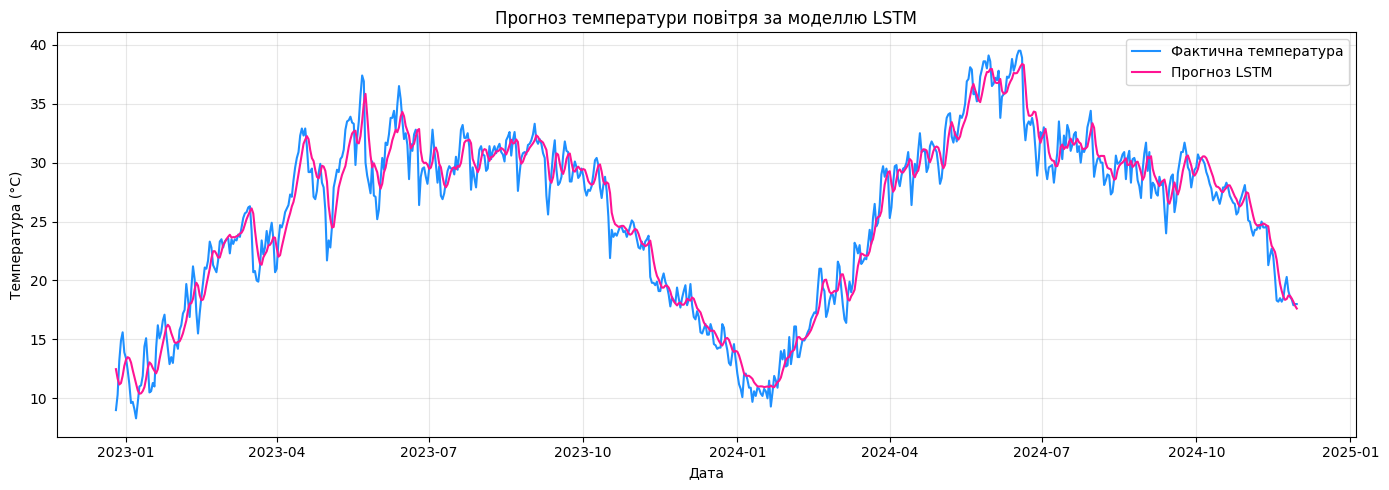

In [37]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize = (14, 5))

plt.plot(test_dates_lstm, y_test_actual,
         label = "Фактична температура",
         color = "dodgerblue", linewidth = 1.5)

plt.plot(test_dates_lstm, pred_lstm,
         label = "Прогноз LSTM",
         color = "deeppink", linewidth = 1.5)

plt.title("Прогноз температури повітря за моделлю LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")

plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

###**Пояснення:**

Побудуємо графік порівняння фактичних значень температури повітря та прогнозу нейронної мережі `LSTM` за допомогою функції `plot()` бібліотеки `Matplotlib`.

Для цього використаємо фактичні значення температури `y_test_actual` та прогнозовані значення `pred_lstm`, відобразивши їх на одному графіку за часовими мітками `test_dates_lstm`.

На отриманому графіку видно, що **модель LSTM досить точно відтворює коливання температури повітря** протягом тестового періоду з 26.12.2022 по 30.11.2024.

Прогнозована крива переважно повторює характер змін фактичних значень температури, хоча спостерігаються незначні відхилення та згладжування окремих максимальних і мінімальних значень.

Отриманий результат узгоджується з раніше обчисленими метриками **MAE = 1,28 °C, RMSE = 1,66 °C та MAPE = 5,63%**, які свідчать про високу точність однокрокового прогнозування нейронної мережі LSTM.

Порівняння моделей

In [38]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами
results = pd.DataFrame({
    "Модель": ["ARIMA(5,1,2)", "Prophet", "LSTM"],
    "MAE": [mae_arima, mae_prophet, mae_lstm],
    "RMSE": [rmse_arima, rmse_prophet, rmse_lstm],
    "MAPE (%)": [mape_arima, mape_prophet, mape_lstm]
})

print("Порівняння точності моделей прогнозування:")
display(results.round(2))

best_model = results.loc[results["MAE"].idxmin(), "Модель"]

print("\nМодель з найменшою похибкою MAE:", best_model)

Порівняння точності моделей прогнозування:


,Модель,MAE,RMSE,MAPE (%)
0,"ARIMA(5,1,2)",10.93,12.50,39.59
1,Prophet,2.00,2.59,9.03
2,LSTM,1.28,1.66,5.63



Модель з найменшою похибкою MAE: LSTM


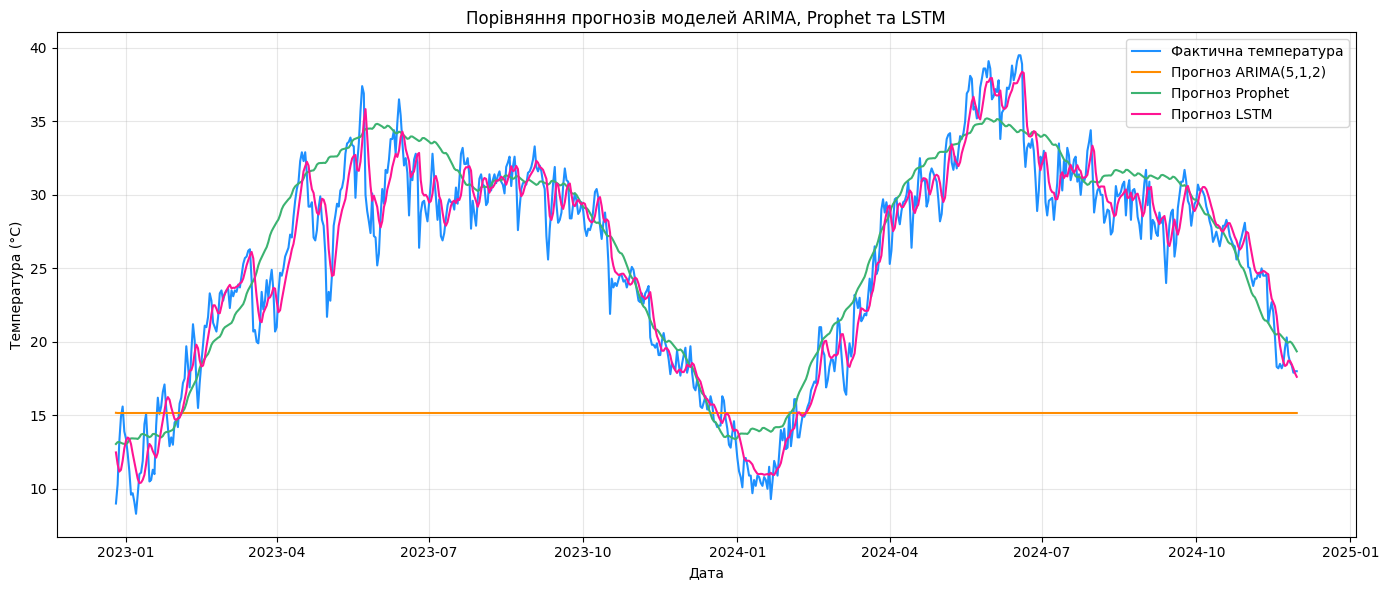

In [41]:
# Побудуйте порівняльний графік прогнозів ARIMA, Prophet та LSTM
actual_series = pd.Series(test.values, index = test.index)

arima_series = pd.Series(forecast_arima.values, index = test.index)

prophet_series = pd.Series(
    pred_prophet, index = test_prophet["ds"]
)

lstm_series = pd.Series(pred_lstm, index = test_dates_lstm)

actual_series = actual_series.groupby(level = 0).mean()
arima_series = arima_series.groupby(level = 0).mean()
prophet_series = prophet_series.groupby(level = 0).mean()
lstm_series = lstm_series.groupby(level = 0).mean()

compare_forecasts = pd.concat([
    actual_series,
    arima_series,
    prophet_series,
    lstm_series
], axis = 1)

compare_forecasts.columns = ["Actual", "ARIMA", "Prophet", "LSTM"]

compare_forecasts = compare_forecasts.dropna().sort_index()

plt.figure(figsize = (14, 6))

plt.plot(compare_forecasts.index, compare_forecasts["Actual"],
         label = "Фактична температура",
         color = "dodgerblue", linewidth = 1.5)

plt.plot(compare_forecasts.index, compare_forecasts["ARIMA"],
         label = "Прогноз ARIMA(5,1,2)",
         color = "darkorange", linewidth = 1.5)

plt.plot(compare_forecasts.index, compare_forecasts["Prophet"],
         label = "Прогноз Prophet",
         color = "mediumseagreen", linewidth = 1.5)

plt.plot(compare_forecasts.index, compare_forecasts["LSTM"],
         label = "Прогноз LSTM",
         color = "deeppink", linewidth = 1.5)

plt.title("Порівняння прогнозів моделей ARIMA, Prophet та LSTM")
plt.xlabel("Дата")
plt.ylabel("Температура (°C)")

plt.legend()
plt.grid(True, alpha = 0.3)
plt.tight_layout()
plt.show()

## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


###**Висновок:**

У результаті проведеного аналізу часових рядів кліматичних даних міста Делі за 2013–2024 роки було встановлено наявність виражених сезонних коливань температури повітря та значної залежності поточних значень температури від попередніх спостережень, що підтверджується результатами аналізу автокореляційних функцій `ACF` та `PACF`.

Для прогнозування температури було побудовано та досліджено три моделі: `ARIMA(5,1,2)`, `Prophet` та `LSTM`.

За результатами оцінювання точності модель `ARIMA` продемонструвала найбільші похибки прогнозування: `MAE` = 10,93 °C, `RMSE` = 12,50 °C та `MAPE` = 39,59%.

Модель `Prophet` показала значно кращі результати з показниками `MAE` = 2,00 °C, `RMSE` = 2,59 °C та `MAPE` = 9,03%, оскільки змогла відтворити основні сезонні закономірності зміни температури.

**Найменші значення похибок отримано для нейронної мережі LSTM**: `MAE` = 1,28 °C, `RMSE` = 1,66 °C та `MAPE` = 5,63%.

На порівняльному графіку видно, що прогноз `LSTM` найближче повторює фактичні температурні коливання, тоді як `Prophet` відтворює загальну сезонну динаміку, а `ARIMA` формує майже постійний прогноз, який суттєво відрізняється від реальних значень.

За отриманими метриками найкращий результат прогнозування продемонструвала модель `LSTM`, яка забезпечила найменші відхилення від фактичних температурних значень.